# 0-instruments: clock-sync

Find where a phone clip starts on the host's clock, and how closely a frame of it can be placed against a line of the host log, so the stage 3 notebooks can put the two side by side.

## Purpose

Stage 3 reads the horn angle from the camera and everything else, duty, current and the pot, from the servo over the bus, logged by the host. The two records have different clocks. The phone stamps its frames and the host stamps its log lines, and nothing ties the two together. This experiment ties them with a clapper. The host flashes the servo's STAT lamp at moments it logs, the camera sees the flashes, and the two sets of times give the offset between the clocks. The scatter of the flashes about a straight line through them is how well a frame can be placed against the log, which is the number stage 3 needs.

The line's slope is the rate of the camera's clock against the host's. Both are crystals, so the two should agree to tens of parts per million, a frame or so over a ten minute clip. The slope is fitted as a check that the clip's time base is what it claims to be, not as a measurement of crystal drift, which a run this short cannot resolve.

The lamp's own delay after the write is not separated out. It is bounded by the host's round trip for the write, which is recorded alongside.

## Procedure

The host side is `osc clapper`, a command of the osc tool. It writes `stat_flash_ticks` to the servo twelve times, with gaps between the writes that differ every time so the flashes match the log in one order only, and prints the host time just before and just after each write. The lamp lights for 2000 control ticks, 100 ms, on each write.

`capture.py` powers the board from the DPS, runs the command, saves its output as `marks.csv`, waits for the clip, runs the extraction, which finds the lamp in the clip and writes its level per frame, and switches the DPS off.

1. The servo board on the bus with a firmware that has the `stat_flash_ticks` register, its power leads on the DPS, the DPS output off. The `osc` tool on the PATH.
2. The phone on its mount, in SLO-MO at 240 fps with the settings in the camera-tag notebook, with the STAT lamp in view. The lamp need not be large in the frame. The DATA lamps on the adapter and on every board blink too, once per bus transaction, for a few milliseconds. The extraction tells STAT from them by the length of its flash.
3. Run `capture.py`. It sets the DPS to the bench rail and turns it on, then asks for the recording to start, runs the flashes, and asks for it to stop. About 20 s of clip.
4. Copy the clip into the capture folder as `lamp.mp4`. The script picks it up, runs the extraction and turns the DPS off.

## Data

- `marks.csv`: one row per flash from `osc clapper`, with `flash`, `t_before` and `t_after`, the host's Unix time either side of the bus write, in seconds.
- `lamp.level.csv`: one row per frame of the clip, with `frame`, the container time `t` in seconds, and `level`, the mean grey level of the lamp box. Written by the extraction.
- `lamp.preview.mp4`, `manifest.json`: the preview and the original's hash, as for every clip. The manifest also records the lamp box the extraction used.
- `lamp.mp4`, the original, not in git.

### marks.csv

The host's record of the flashes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import results, show
import oscnb.fiducial as fd

CAPTURE = Path("../../../telemetry/instruments/clock-sync/capture-1").resolve()

marks = pd.read_csv(CAPTURE / "marks.csv")
marks["latency_ms"] = 1e3 * (marks.t_after - marks.t_before)
show(marks, n=12)
print(f"{len(marks)} flashes over {marks.t_before.iloc[-1] - marks.t_before.iloc[0]:.1f} s; write round trip median {marks.latency_ms.median():.1f} ms, max {marks.latency_ms.max():.1f}")

,flash,t_before,t_after,latency_ms
0,0,1792996135.581,1792996135.581,0.500
1,1,1792996137.282,1792996137.282,0.500
2,2,1792996138.082,1792996138.083,0.500
3,3,1792996140.383,1792996140.384,0.500
4,4,1792996141.584,1792996141.585,0.900
5,5,1792996144.685,1792996144.686,0.500
6,6,1792996145.686,1792996145.687,1.000
7,7,1792996147.187,1792996147.188,1.000
8,8,1792996148.088,1792996148.089,0.500
9,9,1792996149.789,1792996149.789,0.400


12 flashes over 17.3 s; write round trip median 0.5 ms, max 1.0


`t_after` minus `t_before` is the host's round trip for the write: the USB hop to the adapter, the bus transaction, and the hop back. The lamp changes somewhere inside that window. The round trips here are half a millisecond, with one at a millisecond.

### lamp.level.csv

The lamp's grey level per frame, with the box the extraction chose drawn on the first frame of the preview.

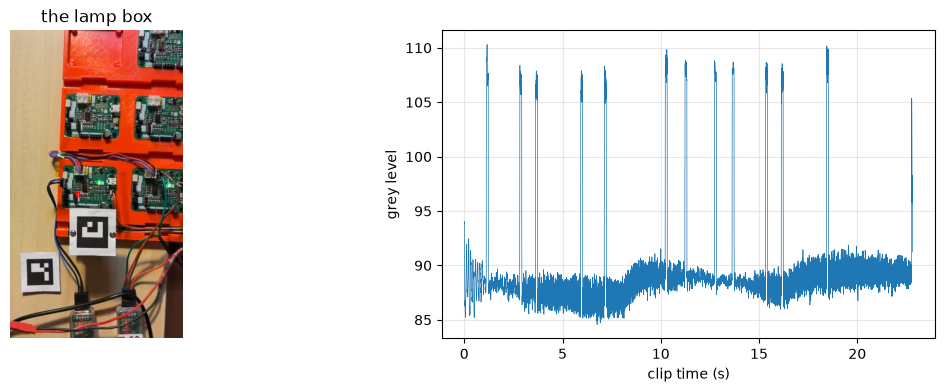

4637 frames over 22.8 s, 203 per second by the container; 837 intervals are double the usual 4 ms, one frame missing at each


In [2]:
manifest = json.loads((CAPTURE / "manifest.json").read_text())
level = pd.read_csv(CAPTURE / "lamp.level.csv")
x, y, w, h = manifest["clips"]["lamp.mp4"]["lamp_roi"]
_, _, img = next(fd.video_frames(CAPTURE / "lamp.preview.mp4"))
m = manifest["clips"]["lamp.mp4"]
sx = img.shape[1] / m["width"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(img[:, :, ::-1]); ax[0].add_patch(plt.Rectangle((x * sx, y * sx), w * sx, h * sx, fill=False, color="red")); ax[0].axis("off"); ax[0].set_title("the lamp box")
ax[1].plot(level.t, level.level, lw=0.5); ax[1].set_xlabel("clip time (s)"); ax[1].set_ylabel("grey level"); ax[1].grid(alpha=0.3)
plt.show()
dt = np.diff(level.t)
gaps = int((dt > 1.5 * np.median(dt)).sum())
print(f"{len(level)} frames over {level.t.iloc[-1]:.1f} s, {m['fps']:.0f} per second by the container; {gaps} intervals are double the usual {1e3 * np.median(dt):.0f} ms, one frame missing at each")

Left, where the extraction found the lamp: the red STAT on the lower left board. Right, its level along the clip. The box is 24 px across and the lamp a few of them, so a flash lifts the mean of the box by about 20 grey levels, over a floor that wanders a few levels with the phone's exposure. The twelve flashes stand clear of it.

The clip has fewer frames than 240 per second would give. About one interval in six is 8 ms instead of 4, with a frame missing at each. The container's times say when each frame was taken. The frame index times 1/240 does not.

## Method

Each flash in the clip has an onset, the first frame in which the lamp is lit. Each flash in the log has the host's time just before the write. Matched in order, the pairs should lie on a straight line, clip time against host time counted from the first flash. The intercept is where the first flash's host moment falls in the clip. The slope is the rate of the camera's clock against the host's, expected to be one to within tens of parts per million. The scatter about the line is how well a frame can be placed against the log. It folds in the frame interval, the lamp's delay after the write, and the host's jitter.

### Flash onsets in the clip

In [3]:
b = fd.bursts(level.t, level.level, min_gap_s=0.3, min_len_s=0.05)
print(f"{len(b)} flashes in the clip against {len(marks)} logged")
show(b.assign(length_ms=1e3 * (b.off - b.on)), n=12)

12 flashes in the clip against 12 logged


,on,off,length_ms
0,1.121,1.221,100.000
1,2.826,2.922,96.000
2,3.627,3.723,96.000
3,5.928,6.024,96.000
4,7.129,7.225,96.000
5,10.230,10.326,96.000
6,11.226,11.327,101.000
7,12.731,12.827,96.000
8,13.632,13.728,96.000
9,15.333,15.428,95.000


The flashes the lamp trace shows, with their length in the clip. Each should last about 100 ms plus up to one frame.

### The fit

clip time = 1.1242 s + 1.000009 x (host time - 1792996135.581); slope minus one +9 ppm, standard error 93 ppm from the residuals
residual rms 1.59 ms, worst 3.40 ms, against a frame interval of 4.0 ms


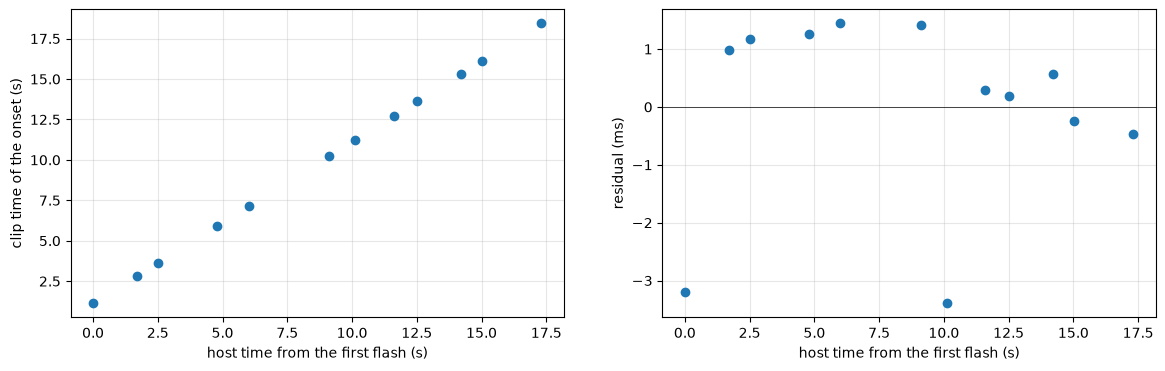

In [4]:
host_t0 = float(marks.t_before.iloc[0])
host = marks.t_before - host_t0
offset_s, rate, rms_s = fd.fit_clock(b.on, host)
resid = b.on - (offset_s + rate * host)
n = len(host)
rate_se = rms_s * np.sqrt(n / (n - 2)) / np.sqrt(((host - host.mean()) ** 2).sum())
print(f"clip time = {offset_s:.4f} s + {rate:.6f} x (host time - {host_t0:.3f}); slope minus one {1e6 * (rate - 1):+.0f} ppm, standard error {1e6 * rate_se:.0f} ppm from the residuals")
print(f"residual rms {1e3 * rms_s:.2f} ms, worst {1e3 * resid.abs().max():.2f} ms, against a frame interval of {1e3 * np.median(dt):.1f} ms")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(marks.t_before - marks.t_before.iloc[0], b.on, "o"); ax[0].set_xlabel("host time from the first flash (s)"); ax[0].set_ylabel("clip time of the onset (s)"); ax[0].grid(alpha=0.3)
ax[1].plot(marks.t_before - marks.t_before.iloc[0], 1e3 * resid, "o"); ax[1].axhline(0, color="k", lw=0.5); ax[1].set_xlabel("host time from the first flash (s)"); ax[1].set_ylabel("residual (ms)"); ax[1].grid(alpha=0.3)
plt.show()

Left, the matched onsets on their line. Right, what is left after the line. The frame interval shows as a scatter of up to one frame, and the container's 1 ms time resolution adds to it. A lamp that lags the write by a steady amount hides in the offset. The slope's standard error comes from the residuals and from how far apart in time the flashes are.

## Results

The first flash's host moment falls 1.124 s into the clip, and the flashes lie on their line to within two milliseconds rms, within one frame interval at worst. The slope came out at one within ten parts per million, with a standard error of about a hundred. That is what two crystals should give, and it confirms the container's frame times as the clip's time base.

The result file carries the offset and the host time it is counted from, the slope with its standard error as the bounds, the residual, and the host's write round trip with its range. Stage 3 applies the offset to place frames against the log and takes the residual as the placement error.

In [5]:
results.write("0-instruments", "clock-sync", CAPTURE,
              notes="clip time = offset + rate x (host time - host_t0), from the STAT lamp flashes of osc clapper",
              offset_s=results.quantity(offset_s, unit="s"),
              host_t0=results.quantity(host_t0, unit="s"),
              rate=results.quantity(rate, lo=rate - rate_se, hi=rate + rate_se),
              residual_rms_s=results.quantity(rms_s, unit="s"),
              write_round_trip_s=results.quantity(marks.latency_ms.median() / 1e3, lo=marks.latency_ms.min() / 1e3, hi=marks.latency_ms.max() / 1e3, unit="s"))

PosixPath('stages/0-instruments/clock-sync/results.json')

## Limitations

- The offset holds for this clip only. Every recording starts at its own moment, so stage 3 repeats the flashes inside each clip and fits them again.
- Twelve flashes over 17 s pin the slope to about a hundred parts per million, which is coarser than the difference two crystals can be expected to have. The slope here is a check on the time base, not a measurement of the clocks' rate. If a clip ever runs long enough for tens of parts per million to matter, a frame over ten minutes, flashes at both ends of it would pin the slope well enough to correct for.
- The lamp's delay after the write is inside the offset and cannot be separated from it here. It is bounded by the host's round trip, which the result records, half a millisecond at 1 Mbps.
- The phone dropped about one frame in six at 240 fps on this clip, and its container stamps frames to the millisecond. Both go into the residual. A frame placed against the log by its container time is good to the residual. One placed by its index is not.
- The lamp is a few pixels in this clip, and the extraction found it by the length of its flash rather than by its brightness. A clip where the STAT lamp is hidden, or where another lamp stays lit for 50 ms or longer, would need the box given by hand.

## Open questions

- Is the lamp onset the first lit frame or the first fully lit one? A flash sampled at 240 fps rises over one or two frames. Fitting a threshold crossing instead of the first frame over threshold may halve the scatter.
- Why does the phone drop frames, and does it drop more in a longer or a brighter clip? The stage 3 clips will show, since every one carries its own flashes.

## Conclusion

A frame of the phone's video can be placed against a line of the host log to within two milliseconds rms, and within one frame interval at worst, from twelve flashes of the STAT lamp. That is finer than the frame interval, so the camera's own timing sets the floor, not the clapper. The two clocks run at the same rate as far as this run can tell, to about a hundred parts per million, which is what crystals give and which over a two minute clip comes to a few milliseconds at most. The host's write round trip, half a millisecond, is small against all of it.

The flashes also showed what else blinks on the bench. The adapter and every board carry a DATA lamp that lights for each bus transaction, a few milliseconds at a time, and the first version of the extraction took the brightest of those for the clapper. The STAT lamp is told apart by staying lit for its full 100 ms, and the extraction now looks for that.

Later experiments should take three things from this run.

- Put a dozen flashes inside every clip, at the start, and fit them with the same method. The offset belongs to the clip, and the slope comes free as a check on the clip's time base.
- Place frames by their container time. The phone drops frames, one in six on this clip, so the frame index is not a clock.
- Keep the STAT lamp in view and uncovered, and expect the DATA lamps to blink beside it. The extraction copes, but a clip where it cannot find twelve flashes of the right length needs the lamp box given by hand.